In [1]:
import pandas as pd
from utils import merge_csv_files_in_directory, standardize_labels
from IPython.display import display, HTML

df = merge_csv_files_in_directory()

#remove duplicates
df = df.drop_duplicates(keep='first')

df.drop("pr_title",inplace = True,axis=1)
df.drop("class_names",inplace = True,axis=1)
df.drop("commit_sha",inplace = True,axis=1)
df.drop("commit_message",inplace = True,axis=1)
df.drop("file_path",inplace = True,axis=1)
df.drop("additions",inplace = True,axis=1)
df.drop("deletions",inplace = True,axis=1)

df.drop("created_at",inplace = True,axis=1)
df.drop("closed_at",inplace = True,axis=1)
df.drop("status",inplace = True,axis=1)
df.drop("patch",inplace = True,axis=1)

# Filter rows where 'labels' doesn't contain '|'
#df = df[~df['labels'].str.contains('|', regex=False)]

# Standardize labels
labels = ['bug', 'enhancement', 'performance', 'refactor', 'clean']
df = standardize_labels(df, labels)
resulting_label_count = df['labels'].nunique()

# Display DataFrame with a scrollable table
#display(HTML(df.to_html(max_rows=None, max_cols=None)))

# Count the occurrences of each unique value in the 'lables' column
label_counts = df['labels'].value_counts()

print(label_counts)

df

Files have been merged and saved as merged.csv
labels
enhancement    424
bug            251
Name: count, dtype: int64


,full_repo_name,labels,file_name,content_before,content_after
0,apache/accumulo,bug,Property.java,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
1,apache/accumulo,bug,Compactor.java,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
2,apache/accumulo,bug,IdleProcessMetricsIT.java,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
3,apache/accumulo,bug,Compactor.java,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
4,apache/accumulo,bug,IdleProcessMetricsIT.java,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
...,...,...,...,...,...
678,apache/accumulo,enhancement,SimpleGarbageCollector.java,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
679,apache/accumulo,enhancement,Master.java,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
680,apache/accumulo,enhancement,Monitor.java,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...
681,apache/accumulo,enhancement,TraceServer.java,/*\n * Licensed to the Apache Software Foundat...,/*\n * Licensed to the Apache Software Foundat...


In [2]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression # Classification
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

# Sütun isimlerini kullanarak kodlama işlemleri
le_class = LabelEncoder()
le_repo = LabelEncoder()

# Kodlama işlemleri
df['file_name_encoded'] = le_class.fit_transform(df['file_name'])
df['full_repo_name_encoded'] = le_repo.fit_transform(df['full_repo_name'])

# One-hot encoding ile labels sütununu dönüştürme
df_encoded = pd.get_dummies(df, columns=['labels'])

# Özellikler ve etiketler
X = df_encoded[['file_name_encoded', 'full_repo_name_encoded']]
y = df_encoded.drop(columns=['file_name', 'full_repo_name', 'file_name_encoded', 'full_repo_name_encoded'])
y = y.astype(int) # convert it 0,1     instead of true, false 

# Eğitim ve test setlerine bölme
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #random_state: 0,3074,42

y_train

ValueError: invalid literal for int() with base 10: '/*\n * Licensed to the Apache Software Foundation (ASF) under one\n * or more contributor license agreements.  See the NOTICE file\n * distributed with this work for additional information\n * regard

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
X_test = torch.tensor(X_test.to_numpy(), dtype=torch.float32)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

# Scaling input to have a mean of 0 and a standard deviation of 1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Converting inputs back to tensors
X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)

print(X_train.shape)


In [ ]:
# Create DataLoader
batch_size = 64
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
print(y_train.shape)

In [5]:

# Define the ANN model
class ANNModel(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size):
        super(ANNModel, self).__init__()
        self.hidden1 = nn.Linear(input_size, hidden_sizes[0])
        self.hidden2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
        self.hidden3 = nn.Linear(hidden_sizes[1], hidden_sizes[2])
        self.hidden4 = nn.Linear(hidden_sizes[2], hidden_sizes[3])
        self.output = nn.Linear(hidden_sizes[3], output_size)
        
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.relu(self.hidden1(x))
        x = self.relu(self.hidden2(x))
        x = self.relu(self.hidden3(x))
        x = self.relu(self.hidden4(x))
        x = self.output(x)
        return x


In [6]:
# Initialize the model, loss function, and optimizer
input_size = 2
hidden_sizes = [64, 128, 64, 32]  # Number of neurons in each hidden layer
output_size = resulting_label_count  # classes = number of possible labels

model = ANNModel(input_size, hidden_sizes, output_size)

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-5)


In [7]:

# Train the model
num_epochs = 50
for epoch in range(num_epochs):
    for batch_X, batch_y in train_loader:
        # Forward pass
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        
        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')



Epoch [1/50], Loss: 0.4864
Epoch [2/50], Loss: 0.4449
Epoch [3/50], Loss: 0.4757
Epoch [4/50], Loss: 0.3732
Epoch [5/50], Loss: 0.4306
Epoch [6/50], Loss: 0.3842
Epoch [7/50], Loss: 0.4182
Epoch [8/50], Loss: 0.4445
Epoch [9/50], Loss: 0.3450
Epoch [10/50], Loss: 0.4188
Epoch [11/50], Loss: 0.3778
Epoch [12/50], Loss: 0.3556
Epoch [13/50], Loss: 0.3718
Epoch [14/50], Loss: 0.3813
Epoch [15/50], Loss: 0.4383
Epoch [16/50], Loss: 0.4544
Epoch [17/50], Loss: 0.3614
Epoch [18/50], Loss: 0.3710
Epoch [19/50], Loss: 0.3610
Epoch [20/50], Loss: 0.3549
Epoch [21/50], Loss: 0.3339
Epoch [22/50], Loss: 0.3823
Epoch [23/50], Loss: 0.3932
Epoch [24/50], Loss: 0.3721
Epoch [25/50], Loss: 0.3730
Epoch [26/50], Loss: 0.3725
Epoch [27/50], Loss: 0.3940
Epoch [28/50], Loss: 0.3721
Epoch [29/50], Loss: 0.3415
Epoch [30/50], Loss: 0.3497
Epoch [31/50], Loss: 0.3424
Epoch [32/50], Loss: 0.3975
Epoch [33/50], Loss: 0.3308
Epoch [34/50], Loss: 0.3476
Epoch [35/50], Loss: 0.3071
Epoch [36/50], Loss: 0.3566
E

In [8]:
with torch.no_grad():
    model.eval()
    test_outputs = model(X_test)
    predicted = torch.sigmoid(test_outputs)  # Sigmoid fonksiyonu uygulanmalı
    predicted = (predicted > 0.5).float()  # 0.5'ten büyük olanlar 1, diğerleri 0
    
    accuracy = (predicted == y_test).float().mean()  # Ortalama doğruluk
    print(f'Accuracy: {accuracy:.4f}')

Accuracy: 0.8315


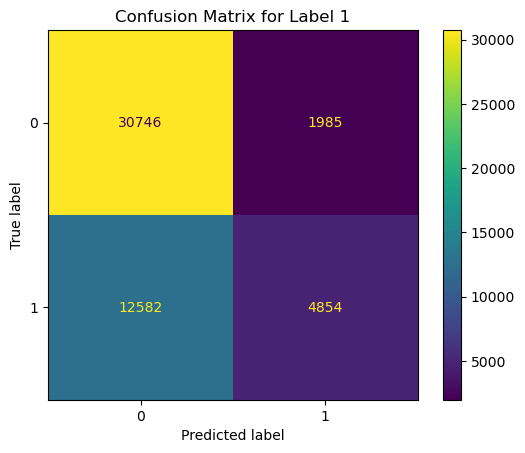

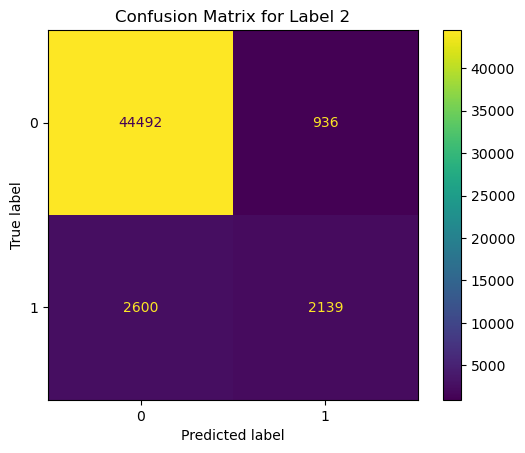

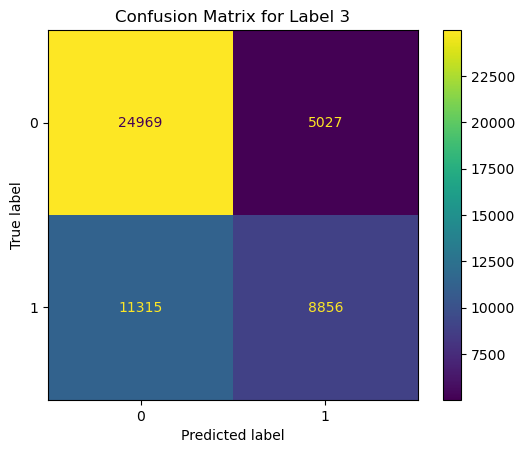

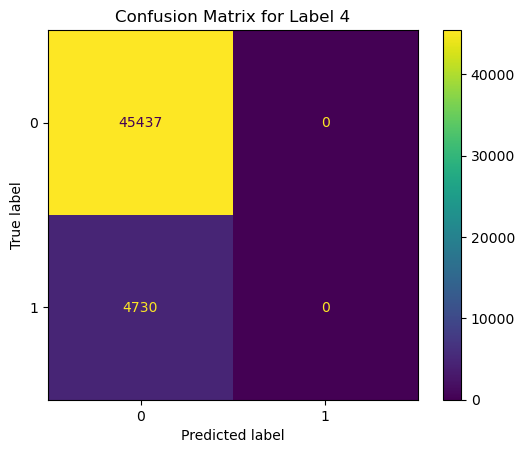

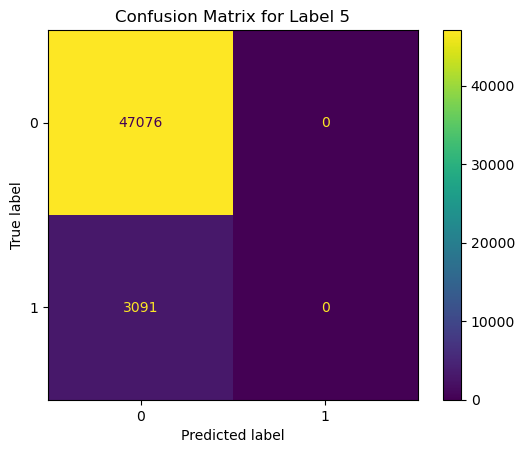

In [9]:
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    import matplotlib.pyplot as plt

    # Convert to numpy arrays
    y_test_np = y_test.numpy()
    predicted_np = predicted.numpy()
    
    # Compute confusion matrix for each label
    confusion_matrices = []
    for i in range(y_test_np.shape[1]):  # Iterate over each label
        cm = confusion_matrix(y_test_np[:, i], predicted_np[:, i])
        confusion_matrices.append(cm)
    
    # Display confusion matrices
    for i, cm in enumerate(confusion_matrices):
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot()
        plt.title(f'Confusion Matrix for Label {i+1}')
        plt.show()

In [10]:
### DEPRECATED ###

In [11]:

# # Örnek tahminler
# sample_data = pd.DataFrame({
#     'file_name': ['ProtoSubject.java','BasicAnnotationProcessor.java'], #1:enhancement, 2:enhancement
#     'full_repo_name': ['google/truth','google/auto']
# })

# # Kodlama işlemleri
# sample_data['file_name_encoded'] = le_class.transform(sample_data['file_name'])
# sample_data['full_repo_name_encoded'] = le_repo.transform(sample_data['full_repo_name'])

# # Özellikleri hazırlama
# X_sample = sample_data[['file_name_encoded', 'full_repo_name_encoded']]
# X_sample = torch.tensor(X_sample.to_numpy(), dtype=torch.float32)

# with torch.no_grad():
#     model.eval()
#     test_outputs = model(X_sample)
#     predicted = torch.sigmoid(test_outputs)  # Sigmoid fonksiyonu uygulanmalı
#     print( predicted)
#     predicted = (predicted > 0.5).float()  # 0.5'ten büyük olanlar 1, diğerleri 0
#     print("after ceiling")
#     print( predicted)